# Stock price forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture. Test will be focused on libraries for crypto market data and stock market data. For more corporate indices (bank indices) maybe there are other libraries to test in a second moment.

### Import modules

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import build_timeseries
import LSTM
import CNN_LSTM
import utils

### Load LOB data

In [2]:
dataset = pd.read_parquet('./Data/LOBSTER/MSFT.parquet')

dataset = dataset[:200000]
# compute the price with the 1st level of the LOB and add the column to the dataset
#dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
#dataset['weighted_price'] = (dataset['P_Ask_1']*dataset['V_Ask_1'] + dataset['P_Bid_1']*dataset['V_Bid_1']) / (dataset['V_Ask_1'] + dataset['V_Bid_1'])
display(dataset)

#plt.figure(figsize=(24,12))
#plt.plot(dataset['mid_price'])
#plt.show()

#targets = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,309900,3788,309500,300,310500,100,309300,3986,310600,100,...,308600,400,311300,100,308500,400,311400,100,308400,1600
1,309900,3788,309500,300,310500,200,309300,3986,310600,100,...,308600,400,311300,100,308500,400,311400,100,308400,1600
2,309900,3788,309500,300,310400,100,309300,3986,310500,200,...,308600,400,311100,4500,308500,400,311300,100,308400,1600
3,309900,3788,309500,300,310400,100,309300,3986,310500,300,...,308600,400,311100,4500,308500,400,311300,100,308400,1600
4,309900,3788,309500,300,310400,100,309300,3986,310500,300,...,308600,400,311100,4500,308500,400,311300,100,308400,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,308300,26720,308100,13361,308400,25432,308000,19380,308500,15631,...,307400,3200,309100,12300,307300,2500,309200,7700,307200,3415
199996,308300,28220,308100,13361,308400,25432,308000,19380,308500,15631,...,307400,3200,309100,12300,307300,2500,309200,7700,307200,3415
199997,308300,26720,308100,13361,308400,25432,308000,19380,308500,15631,...,307400,3200,309100,12300,307300,2500,309200,7700,307200,3415
199998,308300,25520,308100,13361,308400,25432,308000,19380,308500,15631,...,307400,3200,309100,12300,307300,2500,309200,7700,307200,3415


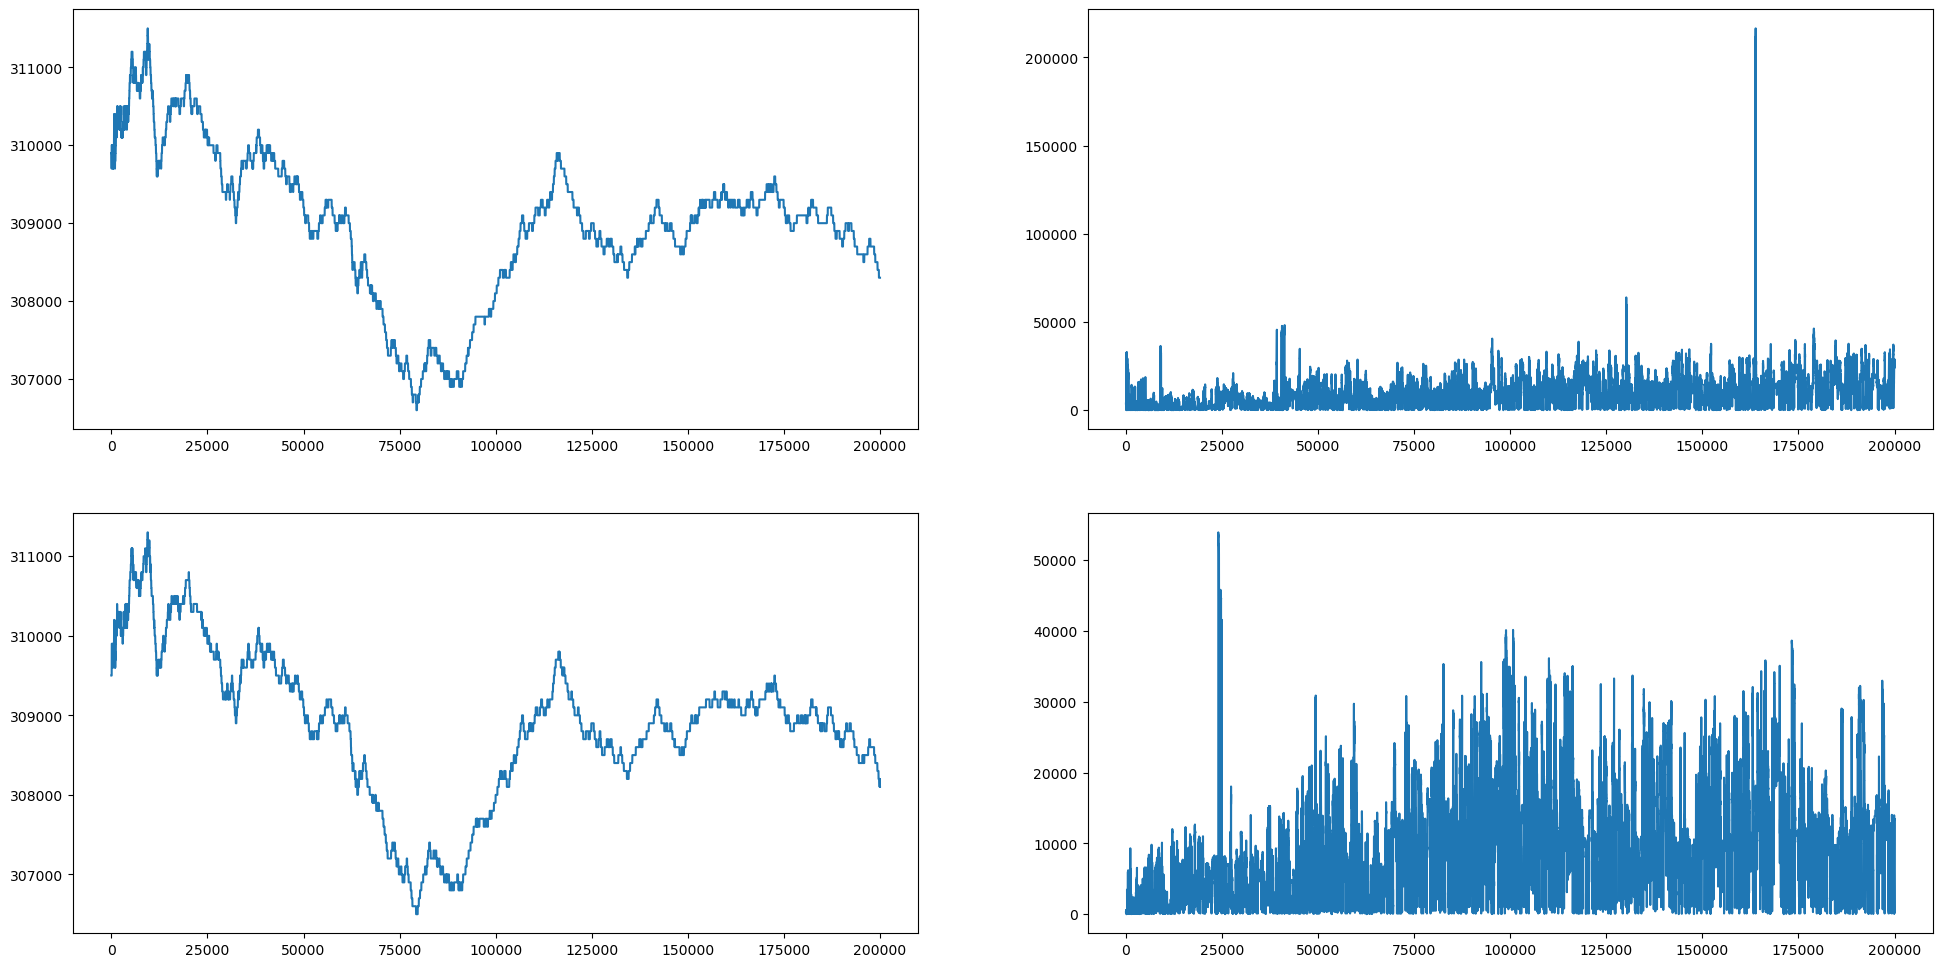

In [3]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

In [3]:
# The StandardScaler scales (to unit variance and removing the mean) 
# each feature column -> features processing
scaler = preprocessing.StandardScaler()
scaler.set_output(transform = 'pandas')
dataset = scaler.fit_transform(dataset)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,0.965379,-0.816847,0.681554,-1.425364,1.496851,-1.419111,0.574744,-1.351160,1.496798,-1.938810,...,0.467854,-1.764183,1.603101,-0.803782,0.467854,-1.576669,1.603065,-0.711306,0.467854,-1.047682
1,0.965379,-0.816847,0.681554,-1.425364,1.496851,-1.408674,0.574744,-1.351160,1.496798,-1.938810,...,0.467854,-1.764183,1.603101,-0.803782,0.467854,-1.576669,1.603065,-0.711306,0.467854,-1.047682
2,0.965379,-0.816847,0.681554,-1.425364,1.390518,-1.419111,0.574744,-1.351160,1.390468,-1.924523,...,0.467854,-1.764183,1.390443,-0.431125,0.467854,-1.576669,1.496738,-0.711306,0.467854,-1.047682
3,0.965379,-0.816847,0.681554,-1.425364,1.390518,-1.419111,0.574744,-1.351160,1.390468,-1.910236,...,0.467854,-1.764183,1.390443,-0.431125,0.467854,-1.576669,1.496738,-0.711306,0.467854,-1.047682
4,0.965379,-0.816847,0.681554,-1.425364,1.390518,-1.419111,0.574744,-1.351160,1.390468,-1.910236,...,0.467854,-1.764183,1.390443,-0.431125,0.467854,-1.576669,1.496738,-0.711306,0.467854,-1.047682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,-0.736130,1.870640,-0.815300,0.425623,-0.736136,1.224830,-0.815290,1.060806,-0.736138,0.280068,...,-0.815280,-1.142346,-0.736140,0.229494,-0.815280,-1.074100,-0.736138,-0.029935,-0.815280,-0.598114
199996,-0.736130,2.046430,-0.815300,0.425623,-0.736136,1.224830,-0.815290,1.060806,-0.736138,0.280068,...,-0.815280,-1.142346,-0.736140,0.229494,-0.815280,-1.074100,-0.736138,-0.029935,-0.815280,-0.598114
199997,-0.736130,1.870640,-0.815300,0.425623,-0.736136,1.224830,-0.815290,1.060806,-0.736138,0.280068,...,-0.815280,-1.142346,-0.736140,0.229494,-0.815280,-1.074100,-0.736138,-0.029935,-0.815280,-0.598114
199998,-0.736130,1.730007,-0.815300,0.425623,-0.736136,1.224830,-0.815290,1.060806,-0.736138,0.280068,...,-0.815280,-1.142346,-0.736140,0.229494,-0.815280,-1.074100,-0.736138,-0.029935,-0.815280,-0.598114


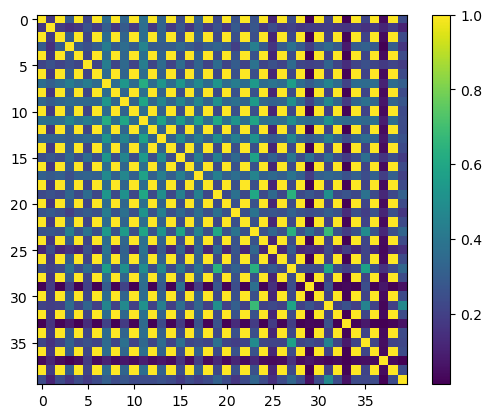

In [5]:
# see the correlation between the features selected
#dataset.corr()
plt.imshow(abs(dataset.corr()))
plt.colorbar()
plt.show()

### Create the effective time-series dataset, and the batch-iterators to process tensors

The procedure is the sliding window procedure

In [17]:
# the final time-series dataset
lookback_period = 10
# Remember to reshape the arrays in order to get the correct tensor structure for convolution: [batch, channels, height, width]
# The standard tensor structure for LSTM layers is [batch, lookback_period, number of features] = [batch, height, width]
Dataset  =  build_timeseries.SlidingWindowDataset(	raw_dataset = dataset, 
													split_rate = 0.7,
													#target_columns = ['P_Ask_1', 'V_Ask_1', 'P_Bid_1', 'V_Bid_1'],
													#target_columns = ['mid_price'],
													target_columns = ['P_Ask_1'],
													#target_columns = targets,
													lookback_period = lookback_period,
													#prediction_horizon = 1,
													channels = False
												)
# in the following lines the features are transformed into torch tensors, within the train and test loaders
trainset =  build_timeseries.CreateLoader(dataset = Dataset.train, transform = None)
testset  =  build_timeseries.CreateLoader(dataset = Dataset.valid, transform = None)
print('Tabelle nel trainset:', len(trainset))
print('Tabelle nel testset :', len(testset))

# dataloaders -> the batch dimension is added as first
trainloader = torch.utils.data.DataLoader(dataset=trainset, batch_size=32, shuffle=True, drop_last=False)
testloader  = torch.utils.data.DataLoader(dataset=testset,  batch_size=32, shuffle=True, drop_last=False)
print(next(iter(trainloader))[0].shape, next(iter(trainloader))[1].shape)
#display(pd.DataFrame(trainset[33][0]))
#display(pd.DataFrame(trainset[33][1]))

Tabelle nel trainset: 139993
Tabelle nel testset : 59997
torch.Size([32, 10, 40]) torch.Size([32, 1, 1])


### Select the model and the parameters

In [20]:
W, H = len(dataset.columns), len(dataset)

#model = LSTM.LSTM1(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = LSTM.LSTM2(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = LSTM.LSTMWithAttention(  input_size=W, 
#                                 encoder_hidden_size=64, 
#                                 encoder_layers=2, 
#                                 decoder_hidden_size=64, 
#                                 decoder_layers=2,
#                                 output_size=1,
#                                 dropout=0.2)

model = CNN_LSTM.LobCNN(lookback_period = lookback_period,
                        inner_convolutional_layers = 2,
                        smoothing_percentage = 0.06,
                        convolution_channels = 32,
                        inception_channels = 64,
                        lstm_layers = 1,
                        output_size = 1
                    )				

### Train the model

In [ ]:
model.to(model.device)
learning_rate = 0.001
epochs = 3
#LOSS = nn.L1Loss()
LOSS = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

t = 0; print("\nStart training...")
train_error = []; test_error = []
train_accuracy = []; test_accuracy = []

while t < epochs:
	model.train()
	start = time.time()
	#for i, data in enumerate(trainloader, 0):
	for inputs, labels in trainloader:
		# get the inputs; data is a list of [inputs, labels]
		#inputs, labels = data
		inputs = inputs.to(model.device)	
		labels = labels.to(model.device)
		# zero the parameter gradients
		optimizer.zero_grad()
		outputs = model(inputs)
		#print(outputs.shape, labels.shape)
		#loss = LOSS(torch.cumsum(outputs, dim=-1), torch.cumsum(labels, dim=-1))
		# for a single output regression:
		loss = LOSS(outputs, labels)
		loss.backward()
		optimizer.step()
	end = time.time()
	print(f'Tempo di calcolo epoca {t}: {end-start}, seconds')
	model.eval()
	error, accuracy = utils.get_performance(dataloader=trainloader, model=model, accname = "train_", loss=LOSS, regression=True)
	train_error.append(error); train_accuracy.append(accuracy)
	error, accuracy = utils.get_performance(dataloader=testloader, model=model, accname = "test_", loss=LOSS, regression=True)
	test_error.append(error); test_accuracy.append(accuracy)

	t += 1

PRINT LOSS FUNCTION, AND THE ACTUAL VS PREDICTED PRICE FOR TRAIN AND TEST SETS

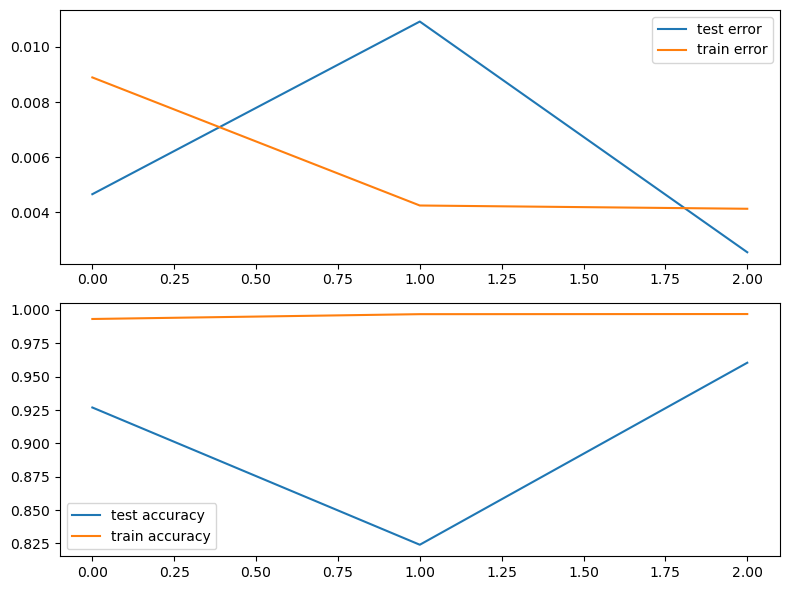

In [ ]:
epochs_list = list(range(0,epochs))
_, axs = plt.subplots(2, 1, figsize=(8,6))
axs[0].plot(epochs_list, test_error,  label = "test error")
axs[0].plot(epochs_list, train_error, label = "train error")
axs[0].legend(loc = 'best')
axs[1].plot(epochs_list, test_accuracy,  label = "test accuracy")
axs[1].plot(epochs_list, train_accuracy, label = "train accuracy")
axs[1].legend(loc = 'best')
plt.tight_layout()
plt.show()

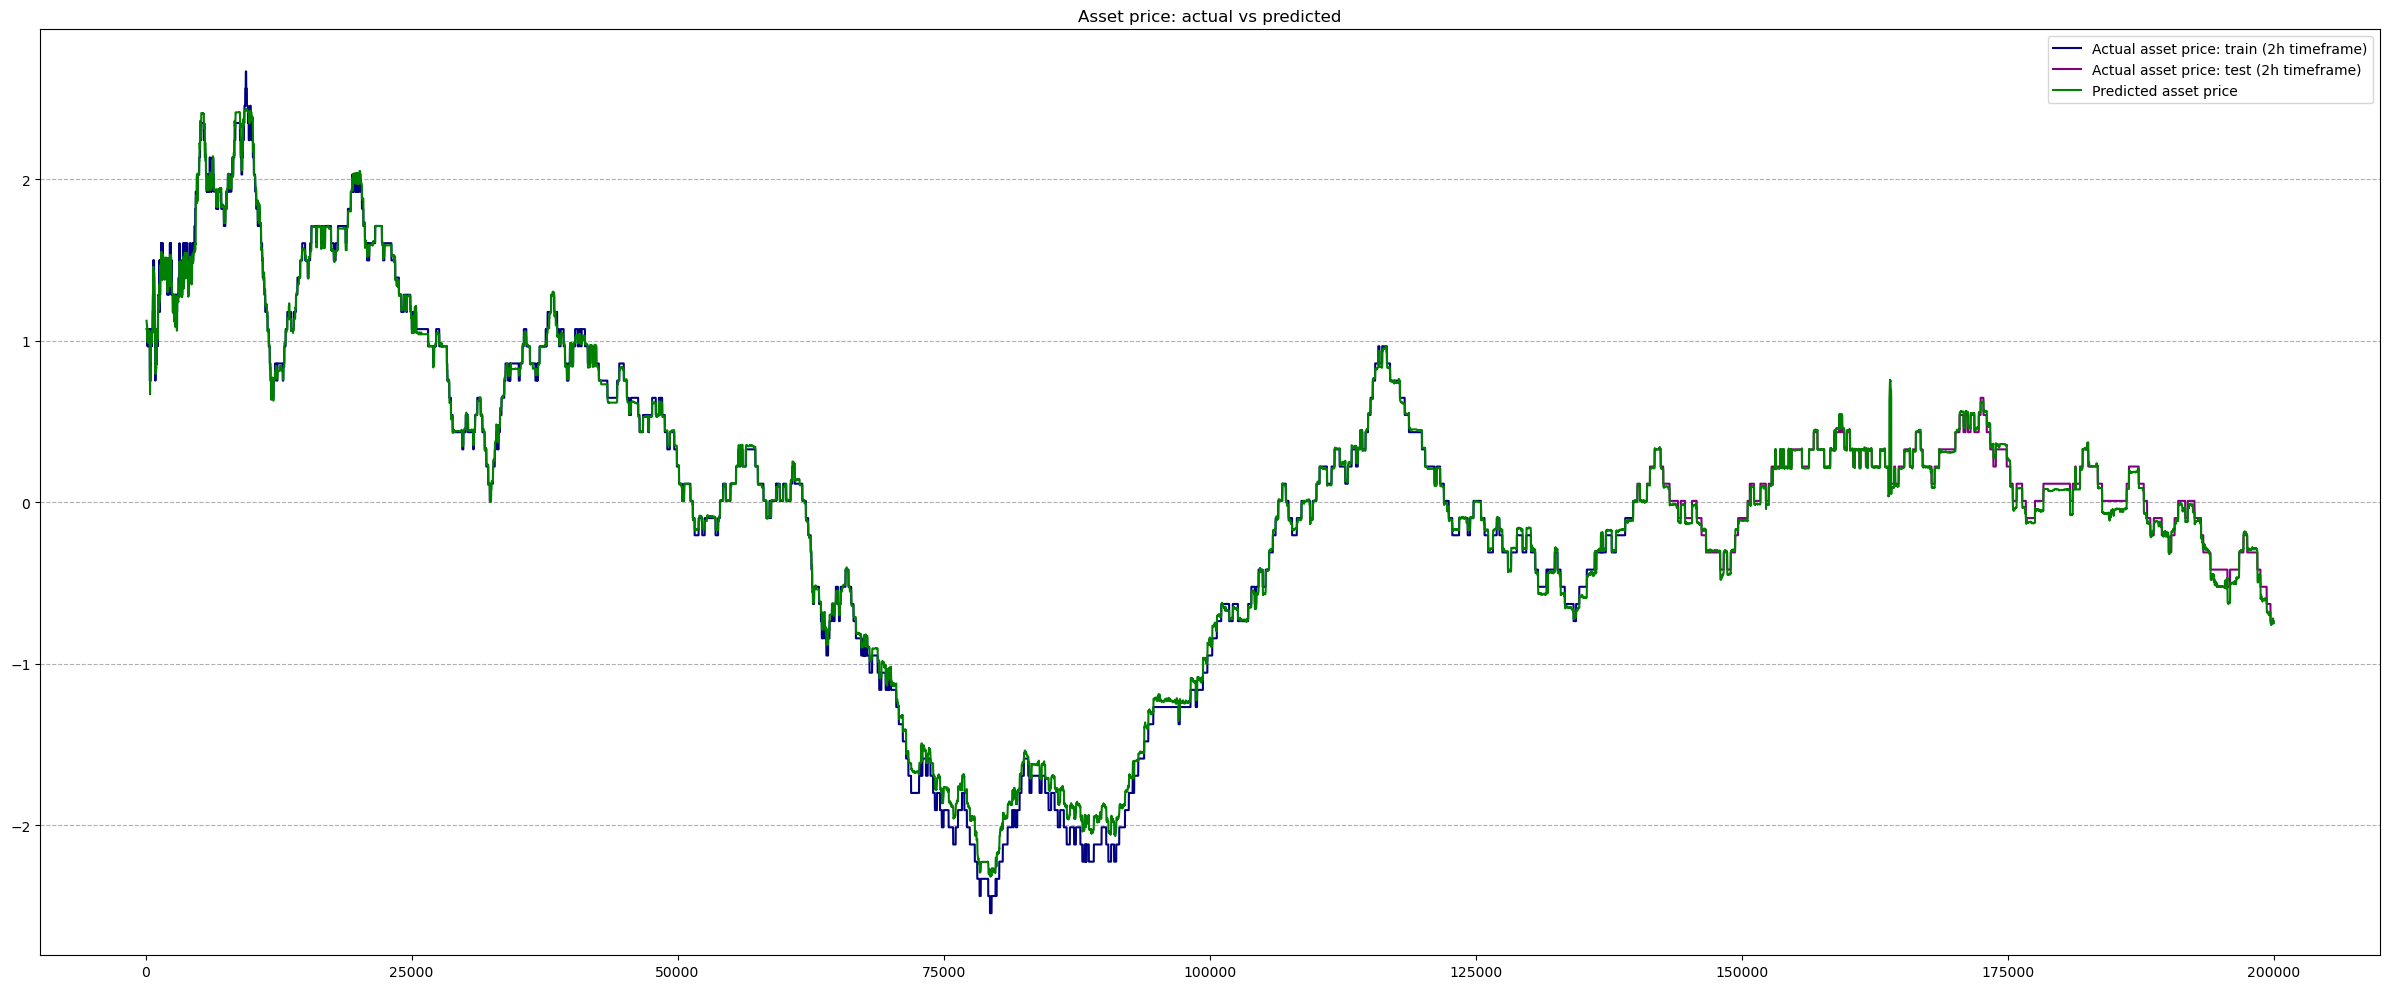

In [ ]:
with torch.no_grad():
    out = list(range(len(Dataset.complete)))
    features = list(range(len(Dataset.complete)))
    for i in range(len(Dataset.complete)):
        features[i] = torch.Tensor(Dataset.complete[i][0])
        features[i] = torch.unsqueeze(features[i], axis = 0)
        features[i] = features[i].to(model.device)
        out[i] = model(features[i]).cpu().squeeze().numpy()

#targets = dataset[lookback_period:]['mid_price']
targets = dataset[lookback_period:]['P_Ask_1']
#targets = targets[lookback_period:]

plt.figure(figsize=(24, 10))
plt.plot(targets[:int(len(targets)*0.7)], label = "Actual asset price: train (2h timeframe)", color = "navy")
plt.plot(targets[int(len(targets)*0.7):], label = "Actual asset price: test (2h timeframe)", color = "purple")
plt.plot(list(range(lookback_period,H)), out, label = "Predicted asset price", color = "green")
plt.title("Asset price: actual vs predicted")
plt.grid(visible=None, which='major', axis='y', linestyle='--')
plt.legend(loc = 'best', prop={'size': 10})
plt.tight_layout()
plt.show()

In [ ]:
for i in range
pass

In [ ]:
model.to(model.device)
learning_rate = 0.001
epochs = 3
#LOSS = nn.L1Loss()
LOSS = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

training_info = utils.batch_gd( model_id='', 
                                model=model, 
                                criterion=LOSS, 
                                optimizer=optimizer, 
                                trainloader=trainloader, 
                                testloader=testloader, 
                                epochs=epochs, 
                                regression=True, 
                                save=False)

Start training...

[--------------------------------------------------] 0.0%  starting epoch 1
Duration of training epoch 1: 219.57974290847778, seconds
Epoch 1/3, Train Loss: 0.00728813, Train Accuracy:  0.99448554, Validation Loss: 0.00061917, Validation Accuracy:  0.99038136, 
[=================---------------------------------] 33.3%  starting epoch 2
Duration of training epoch 2: 180.9258632659912, seconds
Epoch 2/3, Train Loss: 0.00394565, Train Accuracy:  0.99706221, Validation Loss: 0.00034113, Validation Accuracy:  0.99473214, 
[=================================-----------------] 66.7%  starting epoch 3
Duration of training epoch 3: 269.54368257522583, seconds
Epoch 3/3, Train Loss: 0.00374478, Train Accuracy:  0.99721254, Validation Loss: 0.00021158, Validation Accuracy:  0.99672516, 


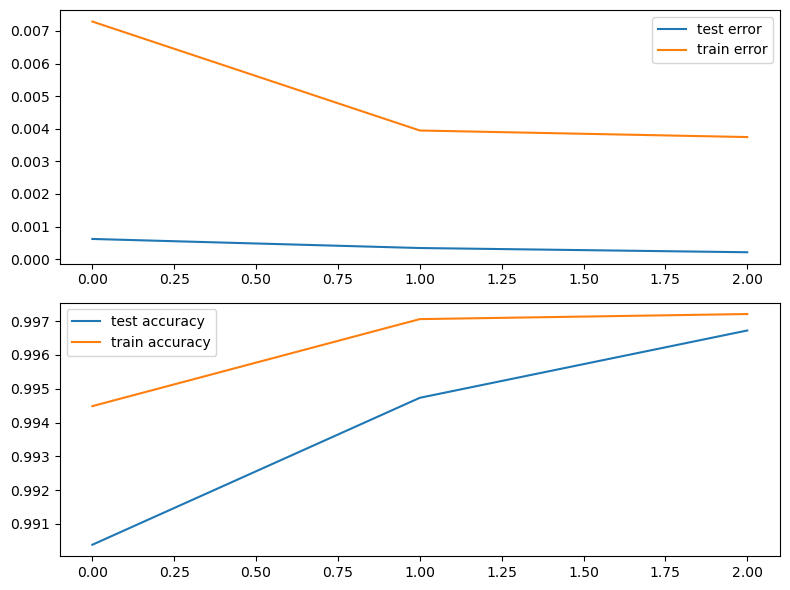

In [ ]:
epochs_list = list(range(0,epochs))
_, axs = plt.subplots(2, 1, figsize=(8,6))
axs[0].plot(epochs_list, training_info['test_loss'],  label = "test error")
axs[0].plot(epochs_list, training_info['train_loss'], label = "train error")
axs[0].legend(loc = 'best')
axs[1].plot(epochs_list, training_info['test_accuracy'],  label = "test accuracy")
axs[1].plot(epochs_list, training_info['train_accuracy'], label = "train accuracy")
axs[1].legend(loc = 'best')
plt.tight_layout()
plt.show()

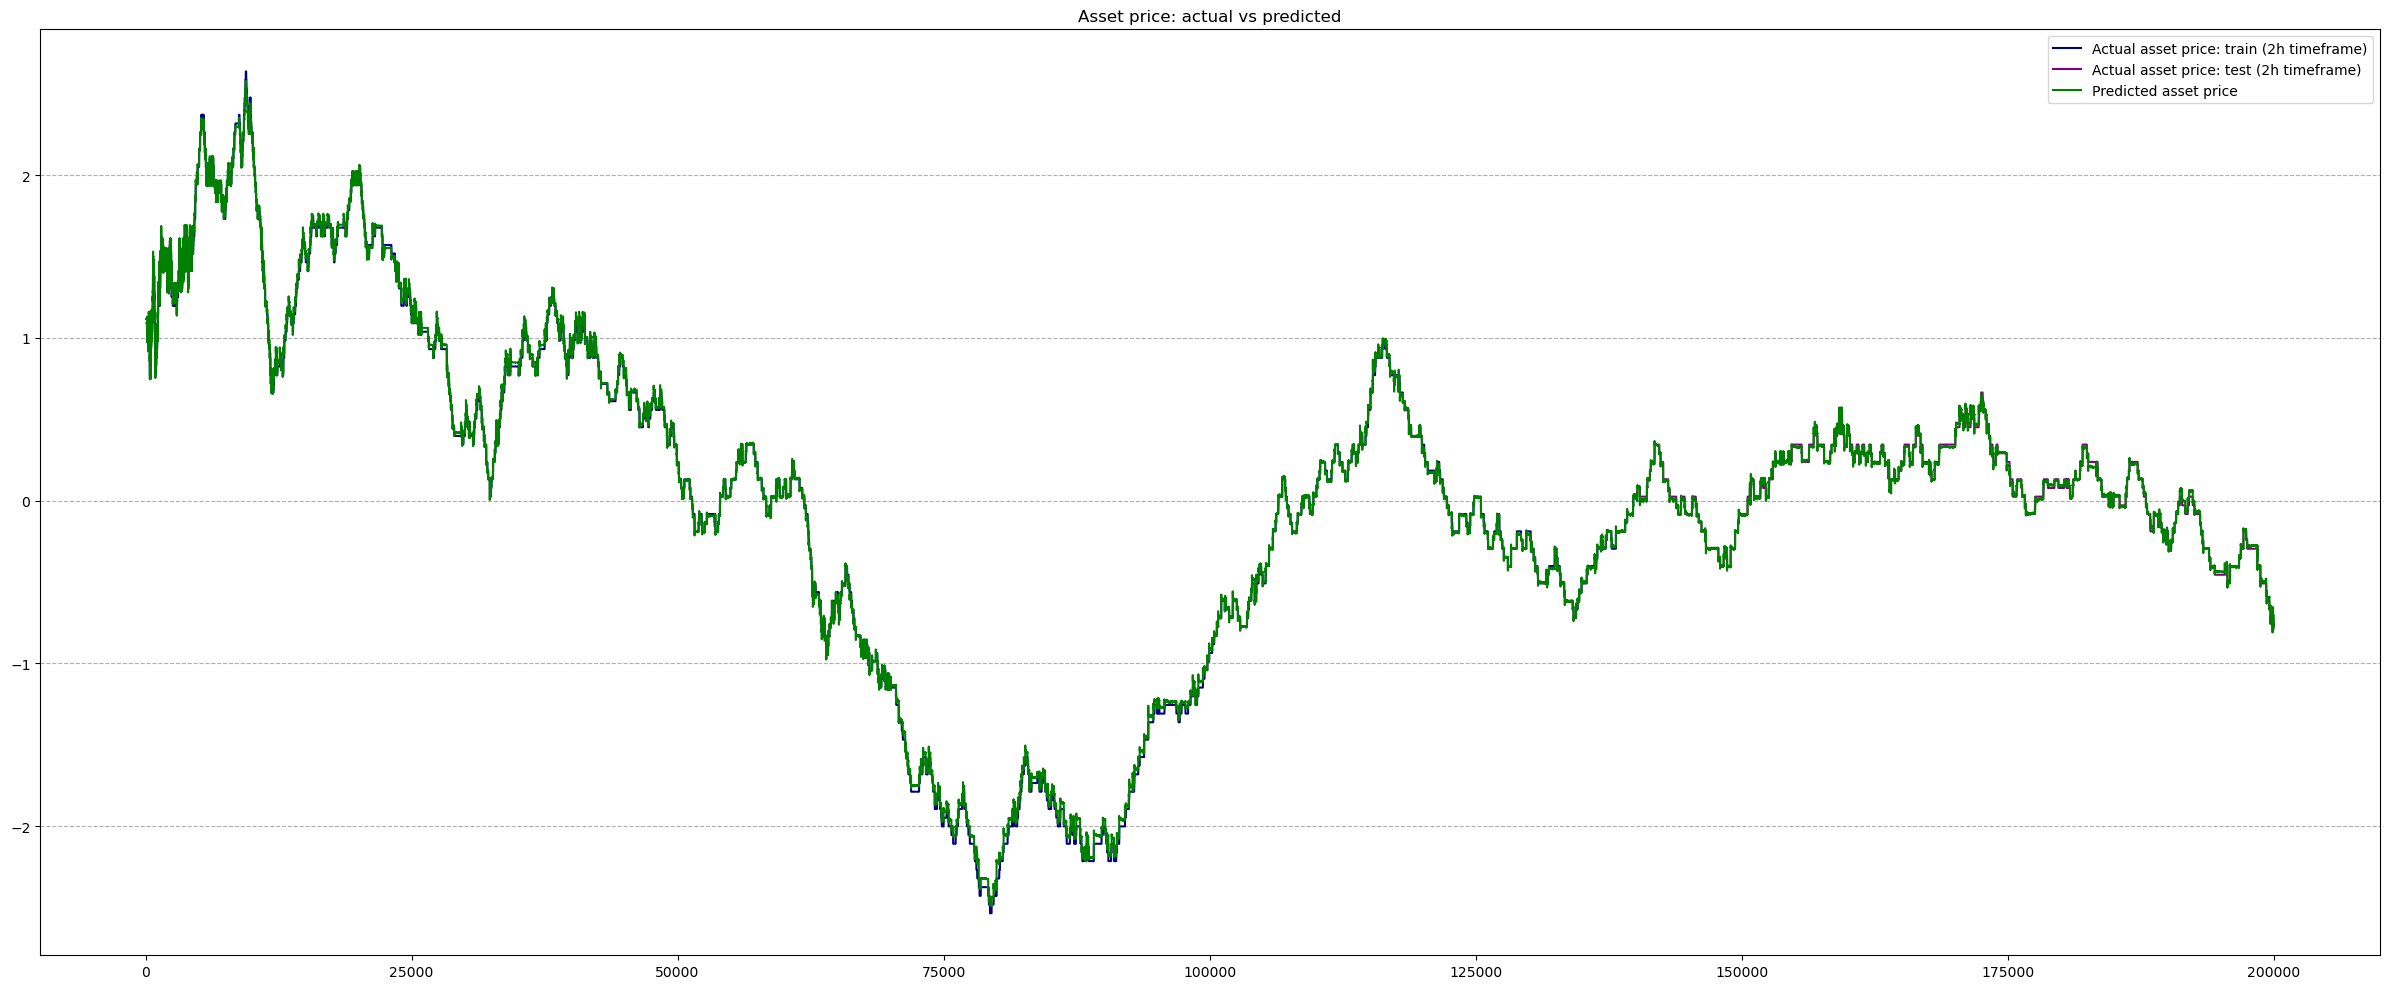

In [ ]:
with torch.no_grad():
    out = list(range(len(Dataset.complete)))
    features = list(range(len(Dataset.complete)))
    for i in range(len(Dataset.complete)):
        features[i] = torch.Tensor(Dataset.complete[i][0])
        features[i] = torch.unsqueeze(features[i], axis = 0)
        features[i] = features[i].to(model.device)
        out[i] = model(features[i]).cpu().squeeze().numpy()

targets = dataset[lookback_period:]['mid_price']
#targets = targets[lookback_period:]

plt.figure(figsize=(24, 10))
plt.plot(targets[:int(len(targets)*0.7)], label = "Actual asset price: train (2h timeframe)", color = "navy")
plt.plot(targets[int(len(targets)*0.7):], label = "Actual asset price: test (2h timeframe)", color = "purple")
plt.plot(list(range(lookback_period,H)), out, label = "Predicted asset price", color = "green")
plt.title("Asset price: actual vs predicted")
plt.grid(visible=None, which='major', axis='y', linestyle='--')
plt.legend(loc = 'best', prop={'size': 10})
plt.tight_layout()
plt.show()